# Before you start :
   - These exercises are related to the Pivot table and correlation lessons.
   - Keep in mind that you need to use some of the functions you learned in the previous lessons.
   - All datasets are provided in the `your-code` folder of this lab.
   - Elaborate your codes and outputs as much as you can.
   - Try your best to answer the questions and complete the tasks and most importantly enjoy the process!!!

#### Import all the libraries that are necessary

In [63]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
from scipy import stats

# Challenge 1

#### Open the ` Employee.csv` file and name your dataset `employee`

In [5]:
url = "Employee.csv"
employee = pd.read_csv(url)
employee.head()

,Name,Department,Education,Gender,Title,Years,Salary
0,Jose,IT,Bachelor,M,analyst,1,35
1,Maria,IT,Master,F,analyst,2,30
2,David,HR,Master,M,analyst,2,30
3,Sonia,HR,Bachelor,F,analyst,4,35
4,Samuel,Sales,Master,M,associate,3,55


#### What's the mean salary by department. 
##### Tip : There are 2 ways to do it - one way is with and the other way is without pivot tables. Do it both ways. 


In [8]:
employee.groupby('Department')["Salary"].mean()

Department
HR       45.00
IT       48.75
Sales    55.00
Name: Salary, dtype: float64

In [9]:
employee.pivot_table(values="Salary", index="Department", aggfunc="mean")


,Salary
Department,
HR,45.00
IT,48.75
Sales,55.00


#### We want now to group the data by more than one column. Use Pandas pivot table function to select the mean salary by department and title

In [10]:
employee.pivot_table(values="Salary", index=["Department", "Title"], aggfunc="mean")


Salary
Department Title            
HR         VP           70.0
           analyst      32.5
IT         VP           70.0
           analyst      32.5
           associate    60.0
Sales      associate    55.0

#### We want to display the number of years of work experience and the salary for each Title. Add Years as a column in your pivot table
*Hint: Use Pandas doc(see References in README.md) to explore the pivot_table() arguments*

In [11]:
employee.pivot_table(values=["Salary", "Years"], index="Title", aggfunc="mean")


,Salary,Years
Title,,
VP,70.000000,8.00
analyst,32.500000,2.25
associate,56.666667,4.00


#### We want to know the information about the mean salary and number of employees in each department and for each job title

In [12]:
employee.pivot_table(
    values="Salary",
    index=["Department", "Title"],
    aggfunc={"Salary": ["mean", "count"]}
)


count  mean
Department Title                 
HR         VP             1  70.0
           analyst        2  32.5
IT         VP             1  70.0
           analyst        2  32.5
           associate      1  60.0
Sales      associate      2  55.0

#### We want to know for each department and for each job title the Salary's median,minimum,maximum and standard deviation. Comment your results

In [13]:
employee.pivot_table(
    values="Salary",
    index=["Department", "Title"],
    aggfunc=["median", "min", "max", "std"]
)


median    min    max       std
                     Salary Salary Salary    Salary
Department Title                                   
HR         VP          70.0     70     70       NaN
           analyst     32.5     30     35  3.535534
IT         VP          70.0     70     70       NaN
           analyst     32.5     30     35  3.535534
           associate   60.0     60     60       NaN
Sales      associate   55.0     55     55  0.000000

#### Based on your comments, fill the missing values with an appropriate value

In several groups (e.g., HR VP, IT VP, IT associate), the standard deviation is missing because there is only one employee in that category. Since a single value has no variation, we replaced these NaNs with 0. This correction does not change the interpretation: those groups simply have no variability in salaries.

In [16]:
pivot = employee.pivot_table(
    values="Salary",
    index=["Department", "Title"],
    aggfunc=["median", "min", "max", "std"]
).fillna(0)

pivot

median    min    max       std
                     Salary Salary Salary    Salary
Department Title                                   
HR         VP          70.0     70     70  0.000000
           analyst     32.5     30     35  3.535534
IT         VP          70.0     70     70  0.000000
           analyst     32.5     30     35  3.535534
           associate   60.0     60     60  0.000000
Sales      associate   55.0     55     55  0.000000

#### The stake holders want to know for each department the number of employees and how much money is spend on salaries. Could you provide that information? 

In [17]:
employee.pivot_table(
    values="Salary",
    index="Department",
    aggfunc=["count", "sum"]
)


,count,sum
,Salary,Salary
Department,,
HR,3,135
IT,4,195
Sales,2,110


#### For each Department and Title, we want to know the the total years of work experience and the mean salary

In [21]:
employee.pivot_table(
    values=["Salary", "Years"],
    index=["Department", "Title"],
    aggfunc={"Years": "sum", "Salary": "mean"}
)

Salary  Years
Department Title                   
HR         VP           70.0      8
           analyst      32.5      6
IT         VP           70.0      8
           analyst      32.5      3
           associate    60.0      7
Sales      associate    55.0      5

#### Bonus

#### We now want to compute the mean salary after removing the maxima for each Department. Create the appropriate pivot table

#### * Hint: Write a custom function*

In [12]:
# your answer here--Your custom function here
        

In [13]:
# your answer here

# Challenge 2

#### Open the ` Fitbit.csv` file and name your dataset `fitbit`

In [23]:
url = "Fitbit.csv"
fitbit = pd.read_csv(url)
fitbit.head()

,Date,Calorie burned,Steps,Distance,Floors,Minutes Sedentary,Minutes Lightly Active,Minutes Fairly Active,Minutes Very Active,Activity Calories,MinutesOfSleep,MinutesOfBeingAwake,NumberOfAwakings,LengthOfRestInMinutes
0,08-05-2015,1934,905,0.65,0,1.355,46,0,0,1680,384,26,23,417
1,09-05-2015,3631,18925,14.11,4,611.000,316,61,60,2248,454,35,21,491
2,10-05-2015,3204,14228,10.57,1,602.000,226,14,77,1719,387,46,25,436
3,11-05-2015,2673,6756,5.02,8,749.000,190,23,4,9620,311,31,21,350
4,12-05-2015,2495,502,3.73,1,876.000,171,0,0,7360,407,65,44,491


#### Explore you dataset in terms of data types and descriptive statistics
#### *Hint: Use Pandas functions from previous lectures*

In [24]:
fitbit.describe()

,Calorie burned,Steps,Distance,Floors,Minutes Sedentary,Minutes Lightly Active,Minutes Fairly Active,Minutes Very Active,Activity Calories,MinutesOfSleep,MinutesOfBeingAwake,NumberOfAwakings,LengthOfRestInMinutes
count,367.000000,367.000000,367.000000,367.000000,367.000000,367.000000,367.000000,367.000000,367.000000,367.000000,367.000000,367.000000,367.000000
mean,2741.501362,10121.588556,8.549128,11.724796,563.934482,236.405995,26.163488,35.722071,2044.147139,290.479564,28.008174,16.196185,321.343324
std,916.307036,5594.836225,3.409881,10.337370,294.793145,86.531376,20.319456,31.006682,2041.267168,154.752328,18.541415,10.757622,170.786726
min,179.000000,0.000000,0.000000,0.000000,1.002000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,2698.000000,6730.500000,6.155000,5.000000,520.000000,179.000000,8.000000,10.500000,1218.500000,224.000000,14.000000,7.000000,248.000000
50%,2974.000000,10413.000000,8.290000,11.000000,663.000000,226.000000,24.000000,29.000000,1553.000000,337.000000,29.000000,16.000000,370.000000
75%,3233.000000,13916.500000,10.560000,16.000000,756.500000,290.000000,41.500000,54.000000,1927.500000,400.500000,41.500000,24.000000,440.500000
max,4351.000000,26444.000000,20.450000,101.000000,998.000000,472.000000,101.000000,153.000000,9830.000000,553.000000,78.000000,45.000000,607.000000


In [26]:
fitbit.dtypes
fitbit.isna().sum()

Date                      0
Calorie burned            0
Steps                     0
Distance                  0
Floors                    0
Minutes Sedentary         0
Minutes Lightly Active    0
Minutes Fairly Active     0
Minutes Very Active       0
Activity Calories         0
MinutesOfSleep            0
MinutesOfBeingAwake       0
NumberOfAwakings          0
LengthOfRestInMinutes     0
dtype: int64

#### You suspect that there must be a linear relationship between the Minutes Very Active and the Steps. Compute the correlation between these variables.

In [33]:
fitbit.columns = fitbit.columns.str.strip()        # remove extra spaces
fitbit.columns = fitbit.columns.str.replace(" ", "_")  # replace spaces with underscores

fitbit.columns



Index(['Date', 'Calorie_burned', 'Steps', 'Distance', 'Floors',
       'Minutes_Sedentary', 'Minutes_Lightly_Active', 'Minutes_Fairly_Active',
       'Minutes_Very_Active', 'Activity_Calories', 'MinutesOfSleep',
       'MinutesOfBeingAwake', 'NumberOfAwakings', 'LengthOfRestInMinutes'],
      dtype='object')

In [38]:
corr = fitbit["Minutes_Very_Active"].corr(fitbit["Steps"])
print(f"r = {corr}")

r = 0.5714518481062608


- moderate-to-strong positive linear relationship:

- More minutes spent “very active” is associated with more steps.

- It’s not perfect (not all variation in steps is explained by active minutes), but it’s a clear signal.

#### Use matplotlib to visually plot Minutes Very active vs Steps. 

##### Hint : import matplotlib.pyplot as plt (See previous lessons)#####
- Use plt.scatter(x=df['col_name_1'], y=df['col_name_2'])

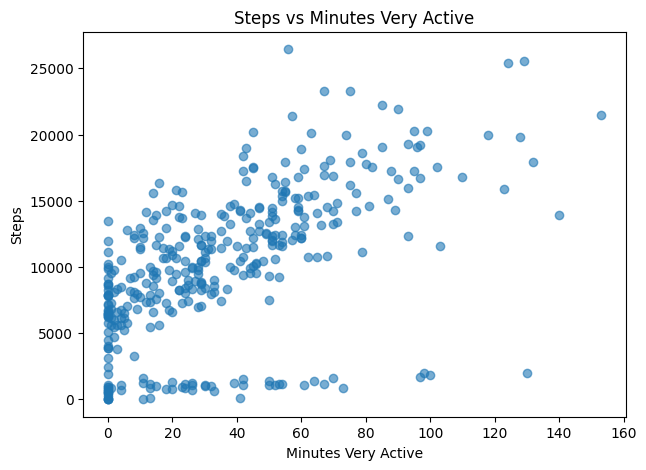

In [41]:
plt.figure(figsize=(7,5))
plt.scatter(x=fitbit["Minutes_Very_Active"], y=fitbit["Steps"], alpha=0.6)

plt.xlabel("Minutes Very Active")
plt.ylabel("Steps")
plt.title("Steps vs Minutes Very Active")
plt.show()

#### What can you say about Minute Very Active and Steps? Write a comment below

- Most points are clustered at low active minutes (<40), but steps vary a lot in that region.

- As Minutes Very Active increases, there’s a visible upward trend in Steps — consistent with your correlation result (~0.57).

- A few outliers (very high steps or very high active minutes) are present but don’t break the overall pattern.

#### We also suspect that there must be a linear relationship between the Minutes Sedentary and the Steps. Compute the correlation between these variables.

In [46]:
corr = fitbit["Minutes_Sedentary"].corr(fitbit["Steps"])
print("Correlation:", corr)


Correlation: 0.07690608062990094


#### Use matplotlib to visually plot Minutes Sedentary vs Steps. Based on the results of the computed correlation and the plot. What can you say about these 2 variables?

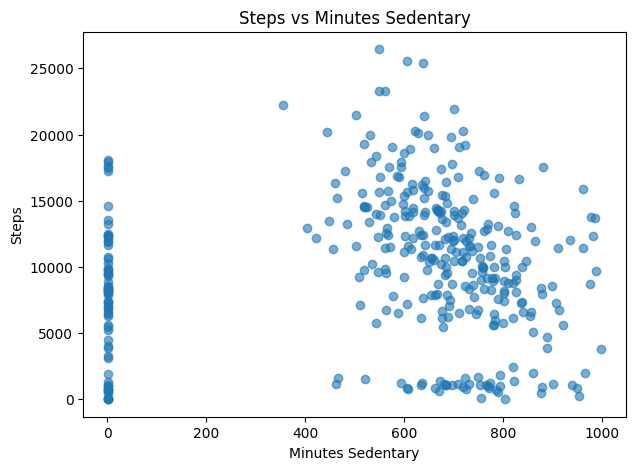

In [43]:
plt.figure(figsize=(7,5))
plt.scatter(x=fitbit["Minutes_Sedentary"], y=fitbit["Steps"], alpha=0.6)

plt.xlabel("Minutes Sedentary")
plt.ylabel("Steps")
plt.title("Steps vs Minutes Sedentary")
plt.show()

The scatterplot of Steps vs Minutes Sedentary shows a wide spread with no clear linear trend. The correlation coefficient (r ≈ 0.08) confirms that there is essentially no linear relationship between sedentary minutes and steps. This suggests that high sedentary time does not necessarily prevent individuals from also achieving high step counts, highlighting the complexity of daily activity patterns.

#### We also suspect that there must be a linear relationship between the MinutesOfSleep and the Steps. Compute the correlation between these variables.

In [ ]:
corr = fitbit["MinutesOfSleep"].corr(fitbit["Steps"])
print("Correlation:", corr)

# no relationship

Correlation: 0.13098565950836383


#### Use matplotlib to visually plot MinutesOfSleep vs Steps. Based on the results of the computed correlation and the plot. What can you say about these 2 variables?

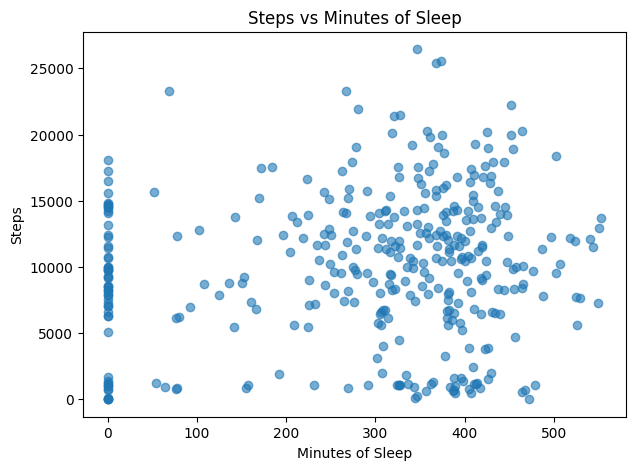

In [52]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7,5))
plt.scatter(x=fitbit["MinutesOfSleep"], y=fitbit["Steps"], alpha=0.6)
plt.xlabel("Minutes of Sleep")
plt.ylabel("Steps")
plt.title("Steps vs Minutes of Sleep")
plt.show()


- The correlation coefficient (r ≈ 0.13) confirms only a very weak positive relationship.

- In practice, this means that step counts are not strongly related to how long someone sleeps — people with high or low step counts can still sleep about the same amount.

#### Select a subset of your dataset with the columns below and compute the correlation matrix. Save the results in the variable `cor_fit`
column= ['Calorie burned', 'Steps','Floors','Minutes Sedentary','Minutes Very Active', 'MinutesOfSleep']

In [54]:
print(fitbit.columns)

Index(['Date', 'Calorie_burned', 'Steps', 'Distance', 'Floors',
       'Minutes_Sedentary', 'Minutes_Lightly_Active', 'Minutes_Fairly_Active',
       'Minutes_Very_Active', 'Activity_Calories', 'MinutesOfSleep',
       'MinutesOfBeingAwake', 'NumberOfAwakings', 'LengthOfRestInMinutes'],
      dtype='object')


In [57]:
cols = ['Calorie_burned', 'Steps', 'Floors', 
        'Minutes_Sedentary', 'Minutes_Very_Active', 'MinutesOfSleep']

df_subset = fitbit[cols]

cor_fit = df_subset.corr()
cor_fit


,Calorie_burned,Steps,Floors,Minutes_Sedentary,Minutes_Very_Active,MinutesOfSleep
Calorie_burned,1.000000,0.255305,0.130757,0.125353,0.197881,0.011485
Steps,0.255305,1.000000,0.306511,0.076906,0.571452,0.130986
Floors,0.130757,0.306511,1.000000,0.057812,0.399503,0.069464
Minutes_Sedentary,0.125353,0.076906,0.057812,1.000000,0.105963,0.204242
Minutes_Very_Active,0.197881,0.571452,0.399503,0.105963,1.000000,0.108018
MinutesOfSleep,0.011485,0.130986,0.069464,0.204242,0.108018,1.000000


#### Based on the result of the correlation matrix. What are the highly correlated features with the variable Steps?
*Hint: From the results above select the variable Steps and order your results in descending order (use Pandas sort_values function)*

In [59]:
cor_fit["Steps"].sort_values(ascending=False)


Steps                  1.000000
Minutes_Very_Active    0.571452
Floors                 0.306511
Calorie_burned         0.255305
MinutesOfSleep         0.130986
Minutes_Sedentary      0.076906
Name: Steps, dtype: float64

# Challenge 3

#### Open the `Time_Grades.csv` file and name your dataset `time_grades`

In [61]:
url = "Time_Grades.csv"
time_grades = pd.read_csv(url)
time_grades


,Name,Study time,Grade
0,Jose,4,4
1,Maria,9,7
2,David,8,9
3,Sonia,10,7
4,Samuel,20,9
5,Eva,5,3
6,Carlos,12,7
7,Pedro,6,5
8,Ana,18,9
9,Gervasio,7,3


#### Show visually the frequency distribution of the time_grades dataset.

In [62]:
time_grades.value_counts()


Name      Study time  Grade
Alicia    11          7        1
Ana       18          9        1
Carlos    12          7        1
Cristina  13          8        1
David     8           9        1
Eva       5           3        1
Gemma     7           8        1
Gervasio  7           3        1
Jonathan  2           1        1
Jose      4           4        1
Maria     9           7        1
Pedro     6           5        1
Pilar     3           2        1
Samuel    20          9        1
Sonia     10          7        1
Name: count, dtype: int64

#### Is there a correaltion between study time and Grade? Use both Pearson and Spearman correlation and comment your results.

In [66]:
# Pearson (linear relationship)
pearson_r, pearson_p = stats.pearsonr(time_grades["Study time"], time_grades["Grade"])
print("Pearson r:", pearson_r, "p:", pearson_p)

Pearson r: 0.7980456073578858 p: 0.000362763525634272


In [68]:
spearman_r, spearman_p = stats.spearmanr(time_grades["Study time"], time_grades["Grade"])

print("Spearman r:", spearman_r, "p:", spearman_p)

Spearman r: 0.819658753036942 p: 0.00018377469445788485


There is a strong positive correlation between study time and grade. Both Pearson’s r (0.80) and Spearman’s ρ (0.82) are high and statistically significant (p < 0.001). This suggests that students who spend more time studying tend to achieve higher grades. Since Spearman’s correlation is slightly higher than Pearson’s, the relationship is strongly monotonic and close to linear, but may not be perfectly linear across all data points

#### Use matplotlib to visually plot Study time vs Grade. Based on the results of the computed correlation and the plot. What can you say about these 2 variables?

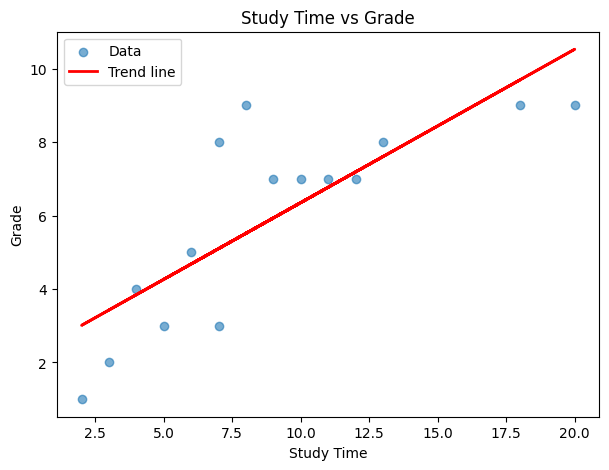

In [69]:
import matplotlib.pyplot as plt
import numpy as np

x = time_grades["Study time"]
y = time_grades["Grade"]

plt.figure(figsize=(7,5))
plt.scatter(x, y, alpha=0.6, label="Data")

# add a regression line
m, b = np.polyfit(x, y, 1)
plt.plot(x, m*x + b, color="red", linewidth=2, label="Trend line")

plt.xlabel("Study Time")
plt.ylabel("Grade")
plt.title("Study Time vs Grade")
plt.legend()
plt.show()


- The scatterplot shows a clear upward trend: more study time → higher grades.

- The regression line highlights the positive linear relationship.

- Pearson’s r ≈ 0.80 and Spearman’s ρ ≈ 0.82 confirm a strong positive, significant correlation.

- Interpretation: “Students who dedicate more time to studying tend to achieve higher grades. The relationship is both linear and monotonic, suggesting that study time is a strong predictor of academic performance.”

#### Could you explain the difference between Pearson and Spearman correlation? (see References in README.md) 

### Pearson correlation (r)

- Measures the strength and direction of a linear relationship.

- Assumes the data is continuous, normally distributed, and the relationship is linear.

- Sensitive to outliers (a few extreme points can pull the correlation up or down).

- Example: if Study Time and Grade increase together in a roughly straight-line way, Pearson will be high.

### Spearman correlation (ρ, rho)

- Measures the strength and direction of a monotonic relationship (not just linear).

- Uses ranks of the data instead of the raw values.

- Less sensitive to outliers, works even when the relationship is curved but consistently increasing/decreasing.

- Example: if Grade increases with Study Time but the relationship flattens out at high study times (not perfectly linear), Spearman will still be high.